<a href="https://colab.research.google.com/github/ricardoasf/Previsao-Series-Temporais/blob/main/RegressaoLASSO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Definição das bibliotecas usadas
import pandas as pd #álgebra linear
import numpy as np #processamento de dados

import matplotlib as mpl
import matplotlib.pyplot as plt #visualização de dados
import seaborn as sns #visualização de dados

############### PARAMETRIZAÇÃO PARA EXECUÇÃO #############
# 1 - para Jupyter/Outras IDEs;
# 2 - para GoogleColab
carga_dados = 2
##########################################################

if carga_dados == 1:
    #Carrega Série Temporal a partir de Planilha de Dados no formato de DataFrame
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    caminho_arquivo = filedialog.askopenfilename()
    df = pd.read_csv(caminho_arquivo)
else:
    #Carrega Dados para GoogleColab
    import io
    from google.colab import files
    uploaded = files.upload()
    #Obtém o nome do arquivo que foi feito upload
    nome_arquivo = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))

df

Saving Dataset3.csv to Dataset3.csv


,Data,Fechamento
0,6/4/2009,0.004050
1,6/5/2009,0.005188
2,6/8/2009,0.005346
3,6/9/2009,0.003923
4,6/10/2009,0.007010
...,...,...
2679,4/9/2020,0.642724
2680,4/13/2020,0.648551
2681,4/14/2020,0.679552
2682,4/15/2020,0.687766


In [2]:
#Transforma a Coluna Data em DateTime
df['DateTime'] = pd.to_datetime(df['Data'])

#Torna a Coluna DateTime o índice do DataFrame
df = df.set_index(df['DateTime'])

#Clona o DataFrame e Normaliza as Colunas pela primeira amostra
df_clone = df[:]
df_clone['Fechamento'] = df['Fechamento'] / df['Fechamento'].iloc[0]

#Copia apenas as colunas de interesse do Clone para o novo DataFrame
df_norm = df_clone[['Fechamento']]
df_norm

,Fechamento
DateTime,
2009-06-04,1.000000
2009-06-05,1.281223
2009-06-08,1.320059
2009-06-09,0.968639
2009-06-10,1.731037
...,...
2020-04-09,158.714480
2020-04-13,160.153340
2020-04-14,167.808842


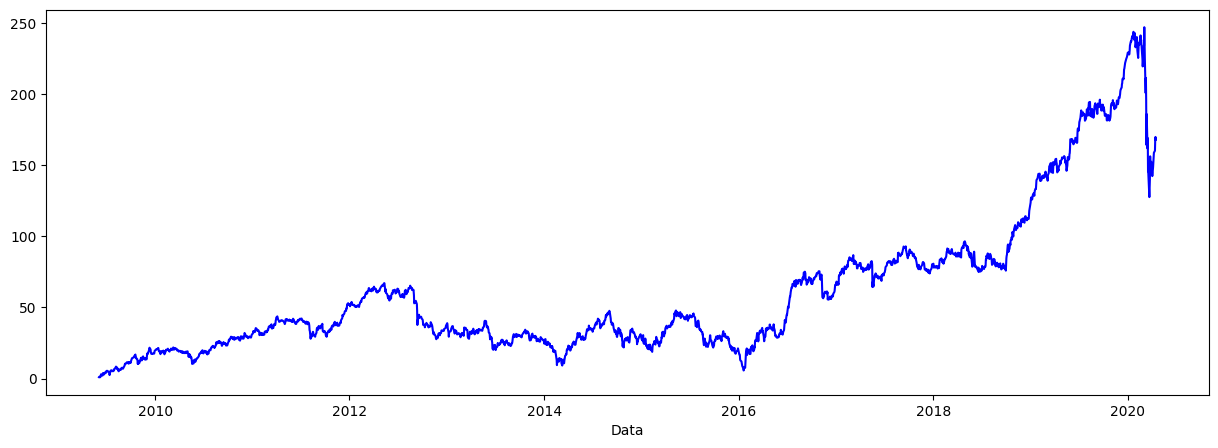

In [3]:
#Análise Gráfica dos Dados
plt.figure(figsize=(15,5))
plt.plot(df_norm['Fechamento'], 'b')
plt.xlabel('Data')
plt.show()

In [15]:
#Clona o DataFrame normalizado para um novo
df_lagged = df_norm[:]

#Determina os atrasos
lags = (1, 2)

#Gera o DataFrame com as Colunas de Atraso
df_lagged = df_norm.assign(**{f'{col}_t-{lag}': df_norm[col].shift(lag) for lag in lags for col in df_norm})

#Exclui valor NaN
df_proc = df_lagged.dropna()

#Mostra dados mais recentes
df_proc

,Fechamento,Fechamento_t-1,Fechamento_t-2
DateTime,,,
2009-06-08,1.320059,1.281223,1.000000
2009-06-09,0.968639,1.320059,1.281223
2009-06-10,1.731037,0.968639,1.320059
2009-06-12,3.035830,1.731037,0.968639
2009-06-15,2.279483,3.035830,1.731037
...,...,...,...
2020-04-09,158.714480,155.817106,151.734174
2020-04-13,160.153340,158.714480,155.817106
2020-04-14,167.808842,160.153340,158.714480


In [23]:
#Define as colunas que serão variáveis de entrada - explicativas
features = df_proc.columns[[1, 2]]
features

Index(['Fechamento_t-1', 'Fechamento_t-2'], dtype='object')

In [24]:
#Define as coluna que será variável de saída - interesse
target = df_proc.columns[[0]]
target

Index(['Fechamento'], dtype='object')

In [25]:
#Separação de Dados para Ajuste e Validação dos Modelos
df_t_ajuste = df_proc['2009-06-04':'2014-06-30'].index.values
df_t_validacao = df_proc['2014-07-01':].index.values
df_dados_ajuste = df_proc['2009-06-04':'2014-06-30']
df_dados_validacao = df_proc['2014-07-01':]

X_ajuste = df_dados_ajuste[features].values
Y_ajuste = df_dados_ajuste[target].values
X_validacao = df_dados_validacao[features].values
Y_validacao = df_dados_validacao[target].values

In [26]:
# Parametrização de Modelo de Regressão LASSO
from sklearn.linear_model import Lasso

#alpha deve ser positivo
#Se alpha = 0, então LASSO = Linear
modelo_Lasso = Lasso(alpha=5).fit(X_ajuste, Y_ajuste)

In [27]:
df_previsto_Lasso = modelo_Lasso.predict(X_validacao)
df_previsto_Lasso_denorm = df_previsto_Lasso * df['Fechamento'].iloc[0]

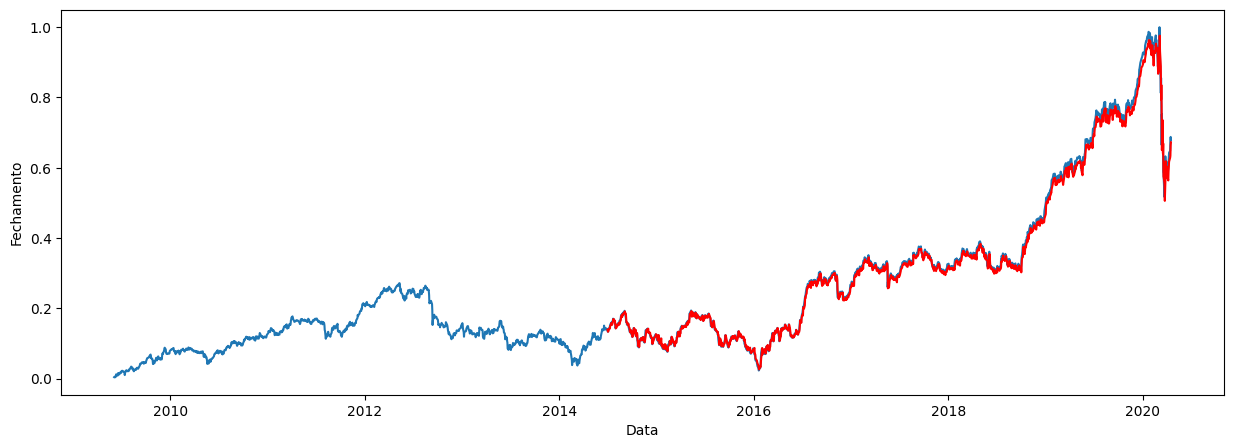

In [28]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Fechamento'])
plt.plot(df_dados_validacao.index, df_previsto_Lasso_denorm, 'r')
plt.ylabel('Fechamento')
plt.xlabel('Data')
plt.show()

In [29]:
r_sq = modelo_Lasso.score(X_validacao, Y_validacao)
print(f"R2: {r_sq}")
print(f"Interceptação: {modelo_Lasso.intercept_}")
print(f"Inclinação: {modelo_Lasso.coef_}")

R2: 0.9964104350991092
Interceptação: [0.89705132]
Inclinação: [0.97231111 0.        ]
